# Extended Study — 5 Detector Families × 4 Datasets

Extends the MVP (`results_deepdive.ipynb`, unchanged) with two more detector families and two more driving datasets. Every number below is loaded from `results/*.json`, produced by `eval.py`.

| Family | Model | Checkpoint |
|---|---|---|
| One-stage CNN, anchor-free (YOLO) | YOLO26-L (NMS-free; also `+NMS` config) | `weights/yolo26l.pt` |
| Query-based transformer (DETR) | RT-DETR-L | `weights/rtdetr-l.pt` |
| Two-stage CNN | Faster R-CNN R50-FPN v2 | torchvision `COCO_V1` |
| Dense one-stage CNN, anchor-based | RetinaNet R50-FPN v2 | torchvision `COCO_V1` |
| Open-vocabulary | YOLO-World-L v2 | `weights/yolov8l-worldv2.pt` |

| Dataset | Split used | Images | Boxes | Classes scored |
|---|---|---|---|---|
| COCO | val2017 | 5,000 | native 2D | 80 |
| KITTI | 1,000 from `training/` (seed 0) | 1,000 | native 2D | car, person (+ cyclist variant) |
| nuImages | v1.0-mini (all keyframes) | 50 | native 2D | person, bicycle, car, motorcycle, bus, truck |
| nuScenes | v1.0-mini, 404 keyframes × 6 cameras | 2,424 | **3D boxes projected to 2D** | same 6 |

Only the **mini** splits of nuImages/nuScenes are downloadable without an account; they are evaluation-only subsets (no training here).

### Requirement checklist (Track A)

| Requirement | Section |
|---|---|
| ≥3 configs, ≥2 families | §1 (5 families, 6 configs) |
| ≥2 datasets + taxonomy mapping | §2 (4 datasets) |
| mAP, AP50/75, AP S/M/L, per-class AP, AR, latency/FPS, memory | §4, §5, §10 |
| Reproducibility | §3 |
| Evidence of running | §3, §4 live inference |
| Cross-dataset generalization | §6, §7 |
| Architecture comparison | §9 |
| Closed-set vs open-vocabulary | §8 |
| Speed–accuracy | §10 |
| Failure analysis | §11 |
| Conclusions, references | §12, §13 |

In [1]:
import os, json, copy, contextlib, io, subprocess, time, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from IPython.display import Markdown, display

pd.set_option("display.precision", 1)
R = Path("results")
DS = {"coco": ("data/coco/annotations/instances_val2017.json", "data/coco/val2017"),
      "kitti": ("data/kitti/kitti_coco.json", "data/kitti/training/image_2"),
      "nuimages": ("data/nuimages/nuimages_coco.json", "data/nuimages"),
      "nuscenes": ("data/nuscenes/nuscenes_coco.json", "data/nuscenes")}
DSN = {"coco": "COCO", "kitti": "KITTI", "nuimages": "nuImages", "nuscenes": "nuScenes"}
MODELS = [("YOLO26-L", "yolo26l"), ("YOLO26-L +NMS", "yolo26l-nms"), ("RT-DETR-L", "rtdetr-l"),
          ("Faster R-CNN v2", "frcnn-r50-fpn-v2"), ("RetinaNet v2", "retinanet-r50-fpn-v2"), ("YOLO-World-L", "yoloworld-l")]
NAMES = [n for n, _ in MODELS]
COLORS = dict(zip(NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
STATS = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]

def load(tag):
    p = R / f"{tag}.json"
    return json.loads(p.read_text()) if p.exists() else None

res = {(n, d): load(f"{t}_{d}") for n, t in MODELS for d in DS}
missing = [k for k, v in res.items() if v is None]
assert not missing, f"missing runs: {missing}"

def quiet(fn, *a, **k):
    with contextlib.redirect_stdout(io.StringIO()):
        return fn(*a, **k)

def run_eval(gt, pred_file, cat_ids=None, img_ids=None):
    E = COCOeval(gt, quiet(gt.loadRes, pred_file), "bbox")
    if cat_ids: E.params.catIds = cat_ids
    if img_ids is not None: E.params.imgIds = img_ids
    quiet(E.evaluate); quiet(E.accumulate); quiet(E.summarize)
    return E

def style(ax):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.tick_params(colors="#6b6a63"); ax.set_axisbelow(True); ax.grid(axis="y", color="#e4e3dd", lw=0.8)

def iou_xywh(a, b):
    iw = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0])); ih = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    i = iw * ih; return i / (a[2] * a[3] + b[2] * b[3] - i + 1e-9)

GT = {d: quiet(COCO, a) for d, (a, _) in DS.items()}
print(len(res), "runs loaded")

24 runs loaded


## 1. Models

| | YOLO26-L | RT-DETR-L | Faster R-CNN v2 | RetinaNet v2 | YOLO-World-L |
|---|---|---|---|---|---|
| Family | one-stage | DETR | two-stage | dense one-stage | open-vocabulary one-stage |
| Backbone / neck | CNN + PAN | HGNetv2 + hybrid encoder | ResNet-50 + FPN | ResNet-50 + FPN | YOLOv8-L CNN + RepVL-PAN, CLIP text encoder |
| Anchors | anchor-free | queries | anchor-based (RPN) | anchor-based (9/location) | anchor-free |
| Classification | 80-way head | 80-way head | 91-way head | 91-way sigmoid (focal loss) | **region–text similarity** with prompt embeddings |
| Training assignment | TAL (one-to-many) + one-to-one | Hungarian | IoU matching | IoU matching | TAL |
| Post-processing | NMS-free (or NMS 0.7) | NMS-free top-k | NMS 0.5 | NMS 0.5 | NMS 0.7 |
| Trained on | COCO | COCO | COCO | COCO | Objects365 + GoldG + CC3M (**no COCO**) |

YOLO-World is prompted with the 80 COCO class names (in COCO order), so its outputs use the same class ids as the closed-set models. On COCO it is therefore **zero-shot**.

In [2]:
pd.DataFrame([{"Model": n, "Params (M)": res[(n, "coco")]["params_M"], "Framework": res[(n, "coco")]["model"]["framework"],
               "Checkpoint": res[(n, "coco")]["model"]["ckpt"]} for n in NAMES]).set_index("Model")

,Params (M),Framework,Checkpoint
Model,,,
YOLO26-L,26.3,ultralytics 8.4.194,weights/yolo26l.pt
YOLO26-L +NMS,26.3,ultralytics 8.4.194,weights/yolo26l.pt
RT-DETR-L,33.0,ultralytics 8.4.194,weights/rtdetr-l.pt
Faster R-CNN v2,43.7,torchvision 0.26.0+cu128,torchvision FasterRCNN_ResNet50_FPN_V2_Weights...
RetinaNet v2,38.2,torchvision 0.26.0+cu128,torchvision RetinaNet_ResNet50_FPN_V2_Weights....
YOLO-World-L,46.8,ultralytics 8.4.194,weights/yolov8l-worldv2.pt


## 2. Datasets and taxonomy mapping

**KITTI → COCO** (`convert_kitti.py`): Car → car, Pedestrian → person. Van, Truck, Misc, Cyclist, Person_sitting, DontCare → ignore region (`iscrowd=1`). Tram dropped.

**nuImages / nuScenes → COCO** (`convert_nuimages.py`, `convert_nuscenes.py`, same mapping):

| nuScenes/nuImages category | → COCO |
|---|---|
| human.pedestrian.{adult, child, construction_worker, police_officer} | person |
| vehicle.car | car |
| vehicle.truck | truck |
| vehicle.bus.{rigid, bendy} | bus |
| vehicle.motorcycle / vehicle.bicycle **without rider** | motorcycle / bicycle |
| vehicle.motorcycle / bicycle **with rider** | ignore (box covers rider + cycle; COCO boxes them separately) |
| vehicle.construction, trailer, emergency.*, pedestrian.{personal_mobility, stroller, wheelchair} | ignore |
| barrier, traffic cone, debris, bicycle rack, animal | dropped |

**nuScenes 2D boxes are projections of 3D boxes**: global → ego → camera, project the 8 corners, take the bounding box of (convex hull ∩ image), as in the devkit's `export_2d_annotations_as_json.py`. They cover the full 3D extent, including occluded parts, so they are looser than hand-drawn boxes. Boxes with visibility `v0-40` (0–40% visible) are ignore regions because many are completely hidden.

*Ignore region* = pycocotools neither rewards nor penalizes detections on it, and never counts it as missed.

In [3]:
rows = []
for d in DS:
    g = GT[d].dataset
    scored = [a for a in g["annotations"] if not a.get("iscrowd")]
    cats = {c["id"]: c["name"] for c in g["categories"]}
    row = {"Dataset": DSN[d], "images": len(g["images"]), "scored boxes": len(scored),
           "ignore boxes": sum(1 for a in g["annotations"] if a.get("iscrowd")),
           "median box h (px)": np.median([a["bbox"][3] for a in scored])}
    for cid, nm in [(1, "person"), (3, "car")]:
        row[f"{nm} boxes"] = sum(1 for a in scored if a["category_id"] == cid)
        row[f"{nm} median h"] = np.median([a["bbox"][3] for a in scored if a["category_id"] == cid] or [np.nan])
    rows.append(row)
pd.DataFrame(rows).set_index("Dataset")

,images,scored boxes,ignore boxes,median box h (px),person boxes,person median h,car boxes,car median h
Dataset,,,,,,,,
COCO,5000,36335,446,61.6,10777,83.1,1918,25.7
KITTI,1000,4441,2371,50.3,534,87.2,3907,46.6
nuImages,50,372,16,65.5,195,73.0,122,52.0
nuScenes,2424,11842,5870,98.6,4023,97.5,6277,94.5


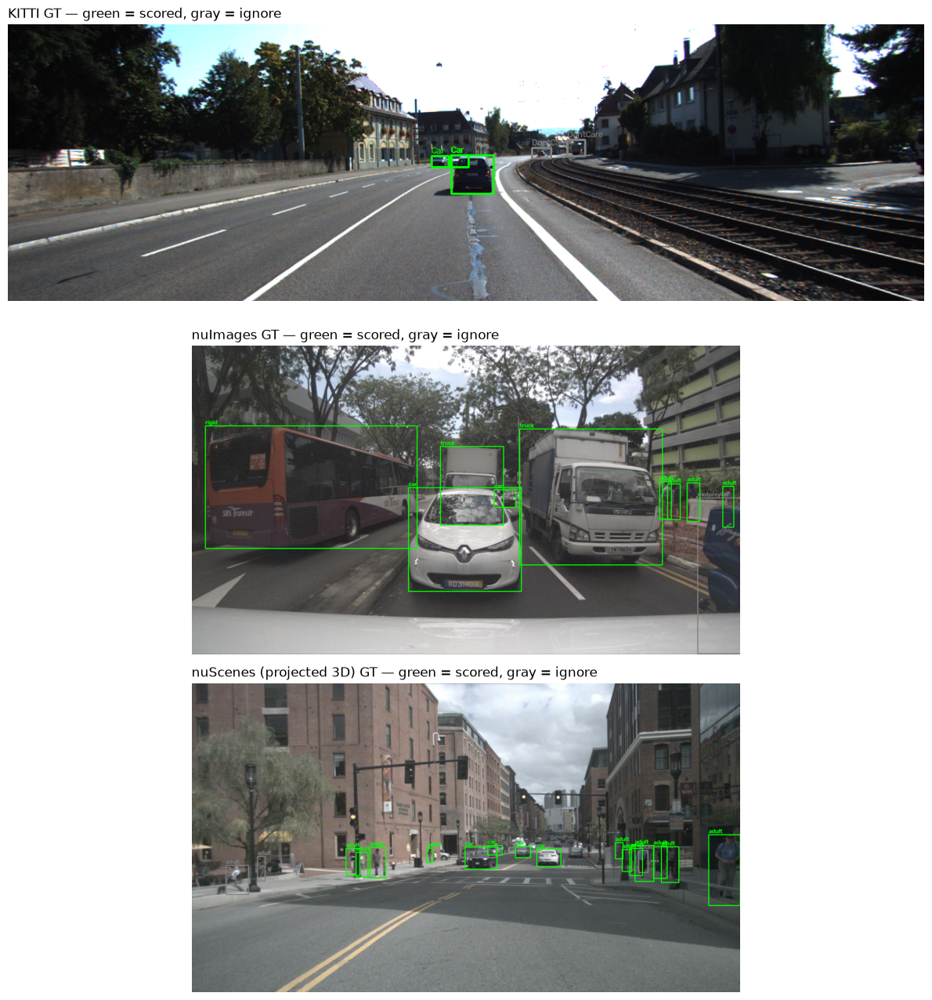

In [4]:
figs = [("KITTI", "kitti_gt_000009.png"), ("nuImages", "nuimages_gt_1.png"), ("nuScenes (projected 3D)", "nuscenes_gt_1213.png")]
fig, axes = plt.subplots(3, 1, figsize=(12, 13))
for ax, (t, f) in zip(axes, figs):
    ax.imshow(cv2.cvtColor(cv2.imread(str(R / "figs" / f)), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{t} GT — green = scored, gray = ignore", loc="left")
plt.tight_layout(); plt.show()

## 3. Reproducibility

In [5]:
import platform, torchvision, ultralytics
print("GPU      :", torch.cuda.get_device_name(), "| driver", subprocess.run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip())
print("Software : Python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| ultralytics", ultralytics.__version__, "| CUDA", torch.version.cuda, "| conda env cnn")
rows = []
for (n, d), r in res.items():
    m = r["model"]
    nms = "none" if (m.get("nms") is False or n == "RT-DETR-L") else f"IoU {m.get('nms_iou', m.get('iou', 0.7))}"
    rows.append({"Model": n, "Dataset": DSN[d], "images": r["dataset"]["num_images"], "resize": m["resize"], "conf": m["conf"],
                 "NMS": nms, "max det": m["max_det"], "command": r["command"]})
pd.DataFrame(rows).set_index(["Model", "Dataset"])

GPU      : NVIDIA GeForce RTX 5080 | driver 595.99.02
Software : Python 3.11.17 | torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | ultralytics 8.4.194 | CUDA 12.8 | conda env cnn


images                             resize     conf  \
Model           Dataset                                                        
YOLO26-L        COCO        5000           letterbox, long side 640  1.0e-03   
                KITTI       1000           letterbox, long side 640  1.0e-03   
                nuImages      50           letterbox, long side 640  1.0e-03   
                nuScenes    2424           letterbox, long side 640  1.0e-03   
YOLO26-L +NMS   COCO        5000           letterbox, long side 640  1.0e-03   
                KITTI       1000           letterbox, long side 640  1.0e-03   
                nuImages      50           letterbox, long side 640  1.0e-03   
                nuScenes    2424           letterbox, long side 640  1.0e-03   
RT-DETR-L       COCO        5000           letterbox, long side 640  1.0e-03   
                KITTI       1000           letterbox, long side 640  1.0e-03   
                nuImages      50           letterbox, long side 640  1.0e-03   
                nuScenes    2424           letterbox, long side 640  1.0e-03   
Faster R-CNN v2 COCO        5000  short side 800, long side <= 1333  1.0e-03   
                KITTI       1000  short side 800, long side <= 1333  1.0e-03   
                nuImages      50  short side 800, long side <= 1333  1.0e-03   
                nuScenes    2424  short side 800, long side <= 1333  1.0e-03   
RetinaNet v2    COCO        5000  short side 800, long side <= 1333  1.0e-03   
                KITTI       1000  short side 800, long side <= 1333  1.0e-03   
                nuImages      50  short side 800, long side <= 1333  1.0e-03   
                nuScenes    2424  short side 800, long side <= 1333  1.0e-03   
YOLO-World-L    COCO        5000           letterbox, long side 640  1.0e-03   
                KITTI       1000           letterbox, long side 640  1.0e-03   
                nuImages      50           letterbox, long side 640  1.0e-03   
                nuScenes    2424           letterbox, long side 640  1.0e-03   

                              NMS  max det  \
Model           Dataset                      
YOLO26-L        COCO         none      300   
                KITTI        none      300   
                nuImages     none      300   
                nuScenes     none      300   
YOLO26-L +NMS   COCO      IoU 0.7      300   
                KITTI     IoU 0.7      300   
                nuImages  IoU 0.7      300   
                nuScenes  IoU 0.7      300   
RT-DETR-L       COCO         none      300   
                KITTI        none      300   
                nuImages     none      300   
                nuScenes     none      300   
Faster R-CNN v2 COCO      IoU 0.5      100   
                KITTI     IoU 0.5      100   
                nuImages  IoU 0.5      100   
                nuScenes  IoU 0.5      100   
RetinaNet v2    COCO      IoU 0.5      100   
                KITTI     IoU 0.5      100   
                nuImages  IoU 0.5      100   
                nuScenes  IoU 0.5      100   
YOLO-World-L    COCO      IoU 0.7      300   
                KITTI     IoU 0.7      300   
                nuImages  IoU 0.7      300   
                nuScenes  IoU 0.7      300   

                                                                    command  
Model           Dataset                                                      
YOLO26-L        COCO          python eval.py --model yolo26l --dataset coco  
                KITTI        python eval.py --model yolo26l --dataset kitti  
                nuImages  python eval.py --model yolo26l --dataset nuimages  
                nuScenes  python eval.py --model yolo26l --dataset nuscenes  
YOLO26-L +NMS   COCO      python eval.py --model yolo26l-nms --dataset coco  
                KITTI     python eval.py --model yolo26l-nms --dataset k...  
                nuImages  python eval.py --model yolo26l-nms --dataset n...  
                nuScenes  python eval.py --mod

Protocol for every run: batch 1, fp32, conf 0.001, pycocotools COCOeval (maxDets 100); latency = end-to-end `predict()` with CUDA sync, first 20 images (10 for nuImages) excluded as warm-up. Commands: `logs/commands.md`; environment: `requirements-lock.txt`.

## 4. Evidence: live inference (same `detectors/` code used by `eval.py`)

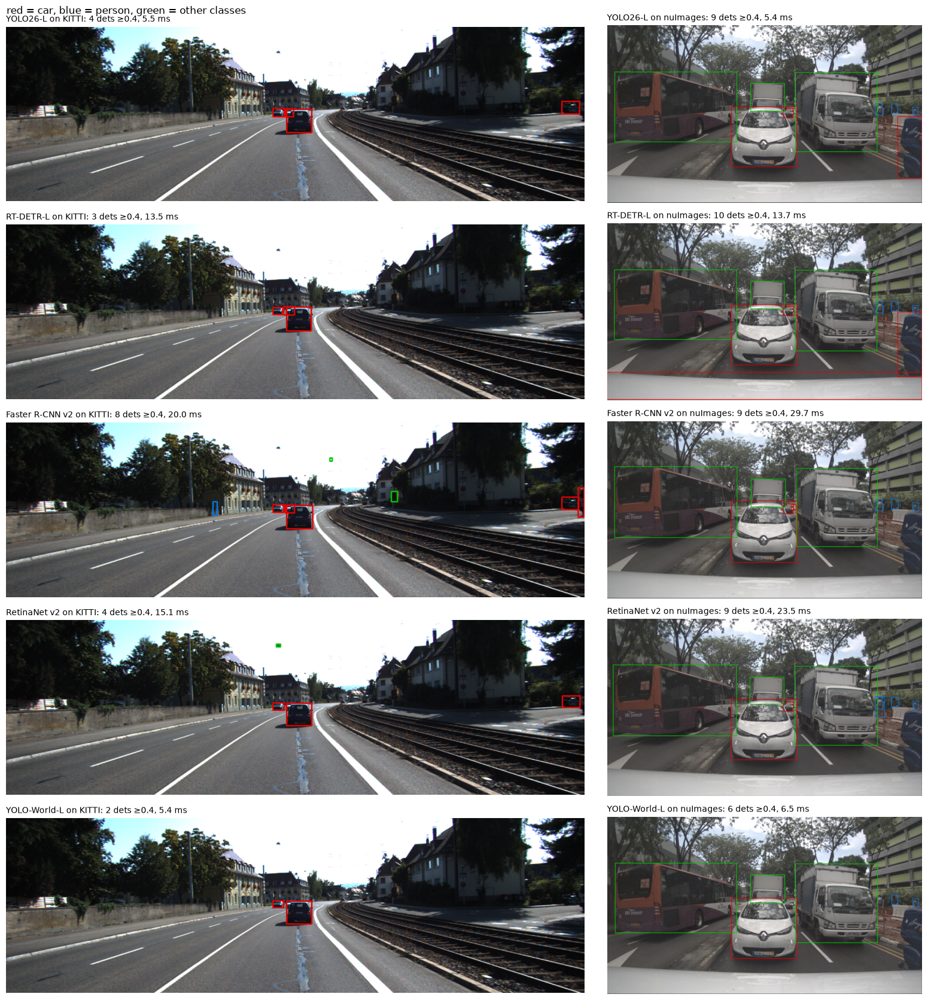

In [6]:
from detectors import load_detector
imgs = {"KITTI": cv2.imread("data/kitti/training/image_2/000009.png"),
        "nuImages": cv2.imread(str(Path("data/nuimages") / GT["nuimages"].imgs[1]["file_name"]))}
keys = [("YOLO26-L", "yolo26l"), ("RT-DETR-L", "rtdetr-l"), ("Faster R-CNN v2", "frcnn"), ("RetinaNet v2", "retinanet"), ("YOLO-World-L", "yoloworld-l")]
fig, axes = plt.subplots(len(keys), 2, figsize=(16, 3.4 * len(keys)), gridspec_kw={"width_ratios": [1.6, 1]})
for row, (name, key) in zip(axes, keys):
    det = load_detector(key)
    for ax, (dname, img) in zip(row, imgs.items()):
        for _ in range(3): det.predict(img)
        torch.cuda.synchronize(); t0 = time.perf_counter(); d = det.predict(img); torch.cuda.synchronize()
        ms = (time.perf_counter() - t0) * 1000; keep = d.scores >= 0.4; vis = img.copy()
        for (x1, y1, x2, y2), c in zip(d.boxes[keep].astype(int), d.cat_ids[keep]):
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 230) if c == 3 else (230, 120, 0) if c == 1 else (0, 200, 0), 2)
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.axis("off")
        ax.set_title(f"{name} on {dname}: {keep.sum()} dets ≥0.4, {ms:.1f} ms", loc="left", fontsize=10)
    del det; torch.cuda.empty_cache()
plt.suptitle("red = car, blue = person, green = other classes", x=0.01, ha="left"); plt.tight_layout(); plt.show()

## 5. Results — all 12 COCO metrics per dataset (×100)

In [7]:
PUBLISHED = {"YOLO26-L": "≈55", "YOLO26-L +NMS": "≈55", "RT-DETR-L": "53.0", "Faster R-CNN v2": "46.7",
             "RetinaNet v2": "41.5", "YOLO-World-L": "zero-shot (docs ≈45–47)"}
for d in DS:
    display(Markdown(f"**{DSN[d]}** — {res[(NAMES[0], d)]['dataset']['num_images']} images"))
    t = pd.DataFrame({n: {k: 100 * v for k, v in res[(n, d)]["metrics"].items()} for n in NAMES}).T[STATS]
    if d == "coco": t["published AP"] = [PUBLISHED[n] for n in t.index]
    display(t)

**COCO** — 5000 images

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR1,AR10,AR100,AR_small,AR_medium,AR_large,published AP
YOLO26-L,53.8,70.7,58.8,37.2,58.0,69.5,39.8,67.0,73.1,57.3,78.0,86.5,≈55
YOLO26-L +NMS,54.0,71.0,58.9,35.9,58.3,69.8,39.0,64.8,69.6,52.2,74.8,83.1,≈55
RT-DETR-L,52.8,71.3,57.2,34.4,57.4,70.8,38.8,65.2,71.7,54.6,75.8,89.0,53.0
Faster R-CNN v2,46.9,67.9,51.3,31.0,50.8,60.3,37.0,59.5,63.0,47.3,66.5,77.4,46.7
RetinaNet v2,41.4,61.6,43.8,26.8,45.7,53.7,33.6,54.1,57.8,40.2,62.0,71.6,41.5
YOLO-World-L,44.7,60.2,48.6,29.2,49.0,57.2,35.7,58.7,63.2,45.5,68.5,76.4,zero-shot (docs ≈45–47)


**KITTI** — 1000 images

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR1,AR10,AR100,AR_small,AR_medium,AR_large
YOLO26-L,39.6,72.9,38.4,23.6,37.9,55.5,17.7,46.1,51.3,41.1,51.0,62.3
YOLO26-L +NMS,39.8,72.7,38.9,23.8,37.8,55.6,18.0,46.0,49.1,38.3,48.2,61.6
RT-DETR-L,40.1,72.5,38.6,25.1,37.3,57.2,17.7,45.7,50.4,43.0,48.3,62.7
Faster R-CNN v2,40.4,74.6,38.3,25.7,38.0,55.4,18.2,47.8,51.5,46.5,49.1,61.9
RetinaNet v2,39.8,73.0,39.1,24.4,37.7,55.3,17.8,45.7,49.2,40.4,48.0,60.8
YOLO-World-L,39.9,72.6,39.2,22.7,37.4,57.2,17.8,45.8,49.6,38.3,48.3,63.0


**nuImages** — 50 images

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR1,AR10,AR100,AR_small,AR_medium,AR_large
YOLO26-L,37.3,53.1,37.2,7.6,27.6,61.3,26.6,47.0,50.5,15.5,45.8,69.1
YOLO26-L +NMS,35.9,51.5,37.3,4.9,25.9,60.3,24.6,41.7,44.0,10.1,33.0,67.6
RT-DETR-L,33.3,52.8,36.2,6.2,28.0,53.1,25.5,42.9,48.5,30.1,45.3,63.0
Faster R-CNN v2,37.7,61.3,35.1,19.9,33.9,54.4,27.0,47.8,49.7,29.5,44.5,63.4
RetinaNet v2,33.4,52.1,36.7,10.4,29.9,48.7,27.9,44.1,46.0,19.7,44.2,58.4
YOLO-World-L,36.3,50.5,37.7,16.4,28.6,58.4,26.9,46.4,48.5,20.9,36.0,71.6


**nuScenes** — 2424 images

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR1,AR10,AR100,AR_small,AR_medium,AR_large
YOLO26-L,17.8,42.6,12.9,1.3,11.5,23.1,17.3,28.7,32.5,14.5,30.6,36.1
YOLO26-L +NMS,17.5,42.0,12.6,1.2,11.1,22.7,16.3,25.8,28.0,7.2,23.6,32.8
RT-DETR-L,17.9,42.7,13.6,1.1,10.6,23.0,17.8,28.5,31.3,16.1,28.9,33.7
Faster R-CNN v2,17.8,43.6,13.0,1.7,11.5,22.2,17.4,28.2,30.1,16.5,29.0,32.2
RetinaNet v2,14.6,37.2,9.6,1.1,8.2,19.4,15.2,24.6,26.9,9.6,24.0,30.4
YOLO-World-L,18.4,43.4,14.3,1.1,11.3,23.9,17.6,29.0,31.5,7.2,27.5,36.1


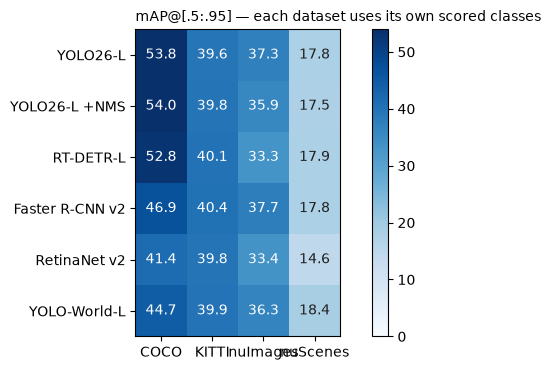

In [8]:
M = pd.DataFrame({DSN[d]: {n: 100 * res[(n, d)]["metrics"]["AP"] for n in NAMES} for d in DS})
fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=M.values.max())
ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks(range(M.shape[0]), M.index)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]; ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if v > 0.6 * M.values.max() else "#1f1f1e")
ax.set_title("mAP@[.5:.95] — each dataset uses its own scored classes", loc="left", fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout(); plt.show()

In [9]:
for d in ("nuimages", "nuscenes"):
    display(Markdown(f"**Per-class AP — {DSN[d]}**"))
    display(pd.DataFrame({n: {k: 100 * v if v is not None else np.nan for k, v in res[(n, d)]["per_class_AP"].items()} for n in NAMES}).T)

**Per-class AP — nuImages**

,person,bicycle,car,motorcycle,bus,truck
YOLO26-L,25.6,47.7,43.3,44.9,23.3,39.1
YOLO26-L +NMS,27.3,44.7,43.8,43.5,20.8,35.3
RT-DETR-L,22.8,36.7,46.1,39.7,22.6,31.7
Faster R-CNN v2,28.9,40.0,45.7,34.4,40.6,36.8
RetinaNet v2,23.4,44.0,41.4,31.4,27.9,32.1
YOLO-World-L,26.3,48.8,45.9,41.1,22.1,33.5


**Per-class AP — nuScenes**

,person,bicycle,car,motorcycle,bus,truck
YOLO26-L,8.6,4.9,29.5,10.6,33.9,19.3
YOLO26-L +NMS,8.7,5.2,29.6,10.1,32.5,18.9
RT-DETR-L,8.7,4.3,30.5,9.5,33.6,20.8
Faster R-CNN v2,8.2,5.5,29.2,8.9,32.9,21.9
RetinaNet v2,9.0,4.2,27.3,5.9,23.8,17.6
YOLO-World-L,8.4,6.0,30.4,11.4,34.6,19.7


## 6. Cross-dataset generalization on shared classes (car + person)

Each dataset scores different classes, so the mAP heatmap above is not apples-to-apples. Here every dataset is re-scored on **car + person only** (KITTI already is).

In [10]:
CP = {}
for n, _ in MODELS:
    for d in DS:
        E = res[(n, d)]["metrics"] if d == "kitti" else None
        if d == "kitti":
            CP[(n, d)] = dict(AP=E["AP"], AP50=E["AP50"], AP75=E["AP75"], S=E["AP_small"], M=E["AP_medium"], L=E["AP_large"],
                              car=res[(n, d)]["per_class_AP"]["car"], person=res[(n, d)]["per_class_AP"]["person"])
        else:
            ev = run_eval(GT[d], res[(n, d)]["pred_file"], [1, 3]); s = ev.stats
            p = ev.eval["precision"][:, :, :, 0, -1]
            pc = {c: float(p[:, :, k][p[:, :, k] > -1].mean()) for k, c in zip(range(2), ("person", "car"))}
            CP[(n, d)] = dict(AP=s[0], AP50=s[1], AP75=s[2], S=s[3], M=s[4], L=s[5], **pc)
cp = pd.DataFrame({(n, DSN[d]): {k: 100 * v for k, v in CP[(n, d)].items()} for n, _ in MODELS for d in DS}).T
cp.index.names = ["Model", "Dataset"]
display(cp["AP"].unstack("Dataset")[[DSN[d] for d in DS]].rename_axis(None, axis=1).style.format("{:.1f}").set_caption("car+person AP"))
display(cp[["car", "person"]].unstack("Dataset").round(1))

,COCO,KITTI,nuImages,nuScenes
Model,,,,
Faster R-CNN v2,54.8,40.4,37.3,18.7
RT-DETR-L,55.9,40.1,34.5,19.6
RetinaNet v2,48.5,39.8,32.4,18.2
YOLO-World-L,55.3,39.9,36.1,19.4
YOLO26-L,59.4,39.6,34.4,19.1
YOLO26-L +NMS,59.4,39.8,35.5,19.2


car                         person                        
Dataset          COCO KITTI nuImages nuScenes   COCO KITTI nuImages nuScenes
Model                                                                       
Faster R-CNN v2  49.9  49.6     45.7     29.2   59.6  31.3     28.9      8.2
RT-DETR-L        50.1  51.3     46.1     30.5   61.7  29.0     22.8      8.7
RetinaNet v2     43.4  49.2     41.4     27.3   53.5  30.4     23.4      9.0
YOLO-World-L     48.3  50.3     45.9     30.4   62.4  29.4     26.3      8.4
YOLO26-L         53.7  49.5     43.3     29.5   65.0  29.6     25.6      8.6
YOLO26-L +NMS    53.6  49.6     43.8     29.6   65.2  30.1     27.3      8.7

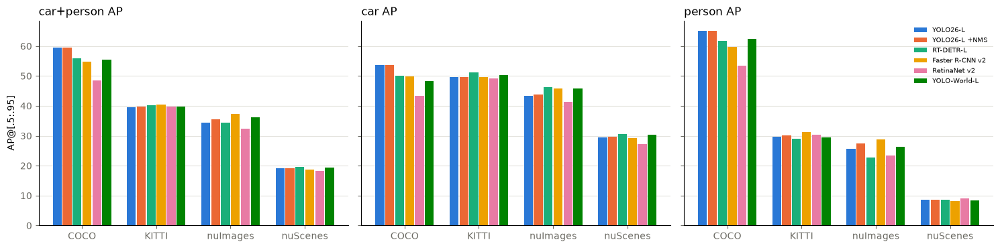

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
dsets = [DSN[d] for d in DS]; w = 0.8 / len(NAMES)
for ax, col, title in zip(axes, ("AP", "car", "person"), ("car+person AP", "car AP", "person AP")):
    for i, n in enumerate(NAMES):
        ax.bar(np.arange(4) + (i - (len(NAMES) - 1) / 2) * w, [cp.loc[(n, d), col] for d in dsets], w * 0.9, color=COLORS[n], label=n)
    ax.set_xticks(range(4), dsets); ax.set_title(title, loc="left"); style(ax)
axes[0].set_ylabel("AP@[.5:.95]"); axes[2].legend(frameon=False, fontsize=7, loc="upper right"); plt.tight_layout(); plt.show()

In [12]:
display(Markdown("**Δ AP by object size, driving dataset − COCO (car + person)**"))
rows = []
for n in NAMES:
    for d in ("kitti", "nuimages", "nuscenes"):
        rows.append({"Model": n, "Dataset": DSN[d], **{s: cp.loc[(n, DSN[d]), s] - cp.loc[(n, "COCO"), s] for s in ("AP", "S", "M", "L")}})
pd.DataFrame(rows).set_index(["Dataset", "Model"]).rename(columns={"S": "Δ small", "M": "Δ medium", "L": "Δ large", "AP": "Δ AP"})

**Δ AP by object size, driving dataset − COCO (car + person)**

,,Δ AP,Δ small,Δ medium,Δ large
Dataset,Model,,,,
KITTI,YOLO26-L,-19.8,-19.6,-33.3,-27.2
nuImages,YOLO26-L,-24.9,-28.1,-42.5,-12.9
nuScenes,YOLO26-L,-40.3,-39.6,-57.8,-57.5
KITTI,YOLO26-L +NMS,-19.6,-19.6,-34.0,-26.0
nuImages,YOLO26-L +NMS,-23.8,-28.9,-41.6,-11.1
nuScenes,YOLO26-L +NMS,-40.2,-39.9,-58.2,-56.8
KITTI,RT-DETR-L,-15.8,-14.5,-30.4,-24.6
nuImages,RT-DETR-L,-21.4,-23.4,-38.1,-15.5
nuScenes,RT-DETR-L,-36.3,-36.6,-53.7,-56.6


## 7. Projected 3D boxes vs native 2D boxes — nuScenes deep dive

nuImages and nuScenes come from the same sensor rig and cities (Boston, Singapore). The main difference is the **box source**: hand-drawn 2D (nuImages) vs projected 3D (nuScenes). Loose projected boxes should hurt strict IoU (AP75) much more than AP50.

In [13]:
rows = []
for n in NAMES:
    for d in ("nuimages", "nuscenes"):
        c = cp.loc[(n, DSN[d])]
        rows.append({"Model": n, "Dataset": DSN[d], "AP50": c["AP50"], "AP75": c["AP75"], "AP": c["AP"], "AP75/AP50": c["AP75"] / c["AP50"]})
pd.DataFrame(rows).set_index(["Model", "Dataset"]).unstack("Dataset").round(2)

AP50              AP75                AP           \
Dataset         nuImages nuScenes nuImages nuScenes nuImages nuScenes   
Model                                                                   
Faster R-CNN v2     62.0     51.5     36.4      9.7     37.3     18.7   
RT-DETR-L           56.6     52.5     35.3     11.2     34.5     19.6   
RetinaNet v2        58.6     51.2     30.3      9.2     32.4     18.2   
YOLO-World-L        55.9     51.1     35.0     11.1     36.1     19.4   
YOLO26-L            54.2     51.7     34.7     10.5     34.4     19.1   
YOLO26-L +NMS       55.9     51.9     36.1     10.5     35.5     19.1   

                AP75/AP50           
Dataset          nuImages nuScenes  
Model                               
Faster R-CNN v2       0.6      0.2  
RT-DETR-L             0.6      0.2  
RetinaNet v2          0.5      0.2  
YOLO-World-L          0.6      0.2  
YOLO26-L              0.6      0.2  
YOLO26-L +NMS         0.7      0.2

In [14]:
def subset_gt(d, keep):
    g = copy.deepcopy(GT[d].dataset)
    for a in g["annotations"]:
        if not a.get("iscrowd") and not keep(a): a["area"] = 1e11  # out of areaRng -> ignored with normal IoU
    c = COCO(); c.dataset = g; quiet(c.createIndex); return c
VIS = {"v40-60": lambda a: a["visibility"] == "v40-60", "v60-80": lambda a: a["visibility"] == "v60-80", "v80-100": lambda a: a["visibility"] == "v80-100"}
vis_gt = {k: subset_gt("nuscenes", f) for k, f in VIS.items()}
cams = sorted({im["camera"] for im in GT["nuscenes"].dataset["images"]})
cam_ids = {c: [im["id"] for im in GT["nuscenes"].dataset["images"] if im["camera"] == c] for c in cams}
rows = []
for n in NAMES:
    pf = res[(n, "nuscenes")]["pred_file"]; row = {"Model": n}
    for k, g in vis_gt.items(): row[("visibility", k)] = 100 * run_eval(g, pf, [1, 3]).stats[0]
    for c in cams: row[("camera", c.replace("CAM_", ""))] = 100 * run_eval(GT["nuscenes"], pf, [1, 3], cam_ids[c]).stats[0]
    rows.append(row)
nv = pd.DataFrame(rows).set_index("Model"); nv.columns = pd.MultiIndex.from_tuples(nv.columns)
print("scored GT per visibility:", {k: sum(1 for a in GT['nuscenes'].dataset['annotations'] if not a['iscrowd'] and f(a)) for k, f in VIS.items()})
display(Markdown("**nuScenes car+person AP by visibility level and by camera**")); nv

scored GT per visibility: {'v40-60': 1725, 'v60-80': 1964, 'v80-100': 8153}


**nuScenes car+person AP by visibility level and by camera**

visibility                camera                             \
                    v40-60 v60-80 v80-100   BACK BACK_LEFT BACK_RIGHT FRONT   
Model                                                                         
YOLO26-L               2.6    5.8    21.9   17.6      28.7       18.4  20.4   
YOLO26-L +NMS          2.7    6.1    22.0   17.5      28.3       18.8  20.5   
RT-DETR-L              2.8    6.6    22.6   18.2      29.9       18.7  21.0   
Faster R-CNN v2        2.8    5.9    21.3   18.3      26.3       16.8  20.5   
RetinaNet v2           2.7    5.4    20.6   18.0      25.8       17.2  20.1   
YOLO-World-L           1.7    4.1    22.7   18.0      29.4       19.2  20.2   

                                        
                FRONT_LEFT FRONT_RIGHT  
Model                                   
YOLO26-L              22.4        18.6  
YOLO26-L +NMS         22.9        18.9  
RT-DETR-L             22.8        18.7  
Faster R-CNN v2       21.5        18.0  
RetinaNet v2          20.8        17.3  
YOLO-World-L          23.7        19.0

In [15]:
# nuScenes scene conditions from scene descriptions (night / rain / day)
meta = lambda n: json.loads((Path("data/nuscenes/v1.0-mini") / f"{n}.json").read_text())
scene_desc = {sc["token"]: sc["description"].lower() for sc in meta("scene")}
sample_scene = {s["token"]: s["scene_token"] for s in meta("sample")}
file_scene = {sd["filename"]: sample_scene[sd["sample_token"]] for sd in meta("sample_data") if sd["is_key_frame"]}
def cond(fn):
    d = scene_desc[file_scene[fn]]
    return "night" if "night" in d else "rain" if "rain" in d else "day"
cond_ids = {}
for im in GT["nuscenes"].dataset["images"]: cond_ids.setdefault(cond(im["file_name"]), []).append(im["id"])
print({k: f"{len(v)} images" for k, v in cond_ids.items()})
pd.DataFrame({n: {c: 100 * run_eval(GT["nuscenes"], res[(n, "nuscenes")]["pred_file"], [1, 3], ids).stats[0] for c, ids in cond_ids.items()}
              for n in NAMES}).T.rename_axis("Model").style.format("{:.1f}").set_caption("nuScenes car+person AP by scene condition")

{'day': '1698 images', 'night': '726 images'}


,day,night
Model,,
YOLO26-L,19.7,18.4
YOLO26-L +NMS,19.8,18.4
RT-DETR-L,20.1,19.1
Faster R-CNN v2,19.5,16.7
RetinaNet v2,19.0,16.4
YOLO-World-L,20.0,18.0


## 8. Closed-set vs open-vocabulary (YOLO-World-L)

1. **Same vocabulary**: YOLO-World prompted with the 80 COCO names vs COCO-trained closed-set models (§5–6). YOLO-World never saw COCO, so its COCO result is zero-shot, while every driving dataset is zero-shot for all models.
2. **Vocabulary the closed-set models don't have**: KITTI `Cyclist` (rider + bike in one box). Variant GT `kitti-cyclist` scores Cyclist as its own class. Closed-set models can only answer with COCO `bicycle` (the bike alone); YOLO-World can be prompted with the word **"cyclist"**.

In [16]:
rows = []
for n, t in MODELS:
    r = load(f"{t}_kitti-cyclist")
    if r: rows.append({"Model": n, "vocabulary": "COCO-80 (cyclist ← 'bicycle')", **{c: 100 * v for c, v in r["per_class_AP"].items()}, "mAP": 100 * r["metrics"]["AP"]})
for p in ("person-cyclist-car", "pedestrian-cyclist-car"):
    r = load(f"yoloworld-l_p-{p}_kitti-cyclist")
    if r: rows.append({"Model": "YOLO-World-L", "vocabulary": "prompts: " + p.replace("-", ", "), **{c: 100 * v for c, v in r["per_class_AP"].items()}, "mAP": 100 * r["metrics"]["AP"]})
pd.DataFrame(rows).set_index(["Model", "vocabulary"])

person  cyclist   car   mAP
Model           vocabulary                                                    
YOLO26-L        COCO-80 (cyclist ← 'bicycle')        25.5  5.6e-02  49.5  25.0
YOLO26-L +NMS   COCO-80 (cyclist ← 'bicycle')        26.5  5.2e-02  49.6  25.4
RT-DETR-L       COCO-80 (cyclist ← 'bicycle')        26.3  2.4e-01  51.3  25.9
Faster R-CNN v2 COCO-80 (cyclist ← 'bicycle')        28.0  1.4e-01  49.6  25.9
RetinaNet v2    COCO-80 (cyclist ← 'bicycle')        26.3  1.8e-01  49.2  25.2
YOLO-World-L    COCO-80 (cyclist ← 'bicycle')        25.9  8.7e-02  50.3  25.4
                prompts: person, cyclist, car        26.9  7.7e-01  50.9  26.2
                prompts: pedestrian, cyclist, car    12.5  2.1e+00  51.0  21.9

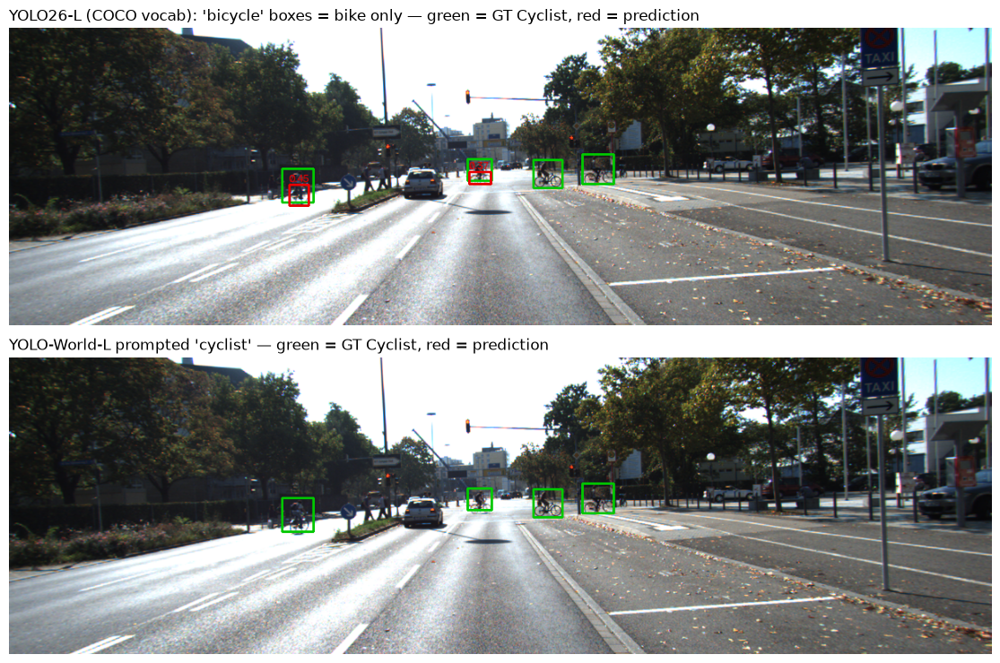

In [17]:
r = load("yoloworld-l_p-person-cyclist-car_kitti-cyclist")
g = GT_c = quiet(COCO, "data/kitti/kitti_coco_cyclist.json")
cyc_imgs = [i for i in g.getImgIds() if any(a["category_id"] == 2 and not a["iscrowd"] for a in g.imgToAnns[i])]
preds = {}
for p in json.loads(Path(r["pred_file"]).read_text()):
    if p["score"] >= 0.3: preds.setdefault(p["image_id"], []).append(p)
rb = {}
for p in json.loads(Path(load("yolo26l_kitti-cyclist")["pred_file"]).read_text()):
    if p["score"] >= 0.3: rb.setdefault(p["image_id"], []).append(p)
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
img_id = max(cyc_imgs, key=lambda i: sum(a["category_id"] == 2 for a in g.imgToAnns[i]))
for ax, (title, pp) in zip(axes, [("YOLO26-L (COCO vocab): 'bicycle' boxes = bike only", rb), ("YOLO-World-L prompted 'cyclist'", preds)]):
    im = cv2.imread(f"data/kitti/training/image_2/{g.imgs[img_id]['file_name']}")
    for a in g.imgToAnns[img_id]:
        if a["category_id"] == 2 and not a["iscrowd"]:
            x, y, w, h = map(int, a["bbox"]); cv2.rectangle(im, (x, y), (x + w, y + h), (0, 200, 0), 2)
    for p in pp.get(img_id, []):
        if p["category_id"] == 2:
            x, y, w, h = map(int, p["bbox"]); cv2.rectangle(im, (x, y), (x + w, y + h), (0, 0, 230), 2)
            cv2.putText(im, f"{p['score']:.2f}", (x, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 230), 1)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(title + " — green = GT Cyclist, red = prediction", loc="left")
plt.tight_layout(); plt.show()

## 9. Architecture comparison — anchors, queries, NMS

Controlled pairs: **Faster R-CNN vs RetinaNet** share ResNet-50-FPN and input size (two-stage vs one-stage); **YOLO26-L vs YOLO26-L +NMS** share weights (NMS-free vs NMS). Duplicates = same-class pairs with IoU > 0.7, both score ≥ 0.3, per 100 detections.

In [18]:
def dup_rate(pred_file):
    by = {}
    for p in json.loads(Path(pred_file).read_text()):
        if p["score"] >= 0.3: by.setdefault(p["image_id"], []).append(p)
    n, dup = 0, 0
    for ps in by.values():
        n += len(ps)
        for i in range(len(ps)):
            for j in range(i + 1, len(ps)):
                dup += ps[i]["category_id"] == ps[j]["category_id"] and iou_xywh(ps[i]["bbox"], ps[j]["bbox"]) > 0.7
    return 100 * dup / max(n, 1)
POST = {"YOLO26-L": "NMS-free (one-to-one)", "YOLO26-L +NMS": "NMS", "RT-DETR-L": "NMS-free (queries)",
        "Faster R-CNN v2": "NMS", "RetinaNet v2": "NMS", "YOLO-World-L": "NMS"}
rows = []
for n in NAMES:
    row = {"Model": n, "post-proc": POST[n]}
    for d in DS:
        m = res[(n, d)]["metrics"]; row[(DSN[d], "AP")] = 100 * m["AP"]; row[(DSN[d], "AR100")] = 100 * m["AR100"]
        row[(DSN[d], "dup/100")] = dup_rate(res[(n, d)]["pred_file"])
    rows.append(row)
arch = pd.DataFrame(rows).set_index(["Model", "post-proc"]); arch.columns = pd.MultiIndex.from_tuples(arch.columns); arch

COCO                KITTI        \
                                         AP AR100  dup/100    AP AR100   
Model           post-proc                                                
YOLO26-L        NMS-free (one-to-one)  53.8  73.1  1.9e+00  39.6  51.3   
YOLO26-L +NMS   NMS                    54.0  69.6  8.1e-02  39.8  49.1   
RT-DETR-L       NMS-free (queries)     52.8  71.7  3.5e+00  40.1  50.4   
Faster R-CNN v2 NMS                    46.9  63.0  0.0e+00  40.4  51.5   
RetinaNet v2    NMS                    41.4  57.8  0.0e+00  39.8  49.2   
YOLO-World-L    NMS                    44.7  63.2  3.1e-03  39.9  49.6   

                                              nuImages               nuScenes  \
                                      dup/100       AP AR100 dup/100       AP   
Model           post-proc                                                       
YOLO26-L        NMS-free (one-to-one)     1.4     37.3  50.5     1.5     17.8   
YOLO26-L +NMS   NMS                       0.0     35.9  44.0     0.0     17.5   
RT-DETR-L       NMS-free (queries)        1.8     33.3  48.5     2.6     17.9   
Faster R-CNN v2 NMS                       0.0     37.7  49.7     0.0     17.8   
RetinaNet v2    NMS                       0.0     33.4  46.0     0.0     14.6   
YOLO-World-L    NMS                       0.0     36.3  48.5     0.0     18.4   

                                                     
                                      AR100 dup/100  
Model           post-proc                            
YOLO26-L        NMS-free (one-to-one)  32.5     1.8  
YOLO26-L +NMS   NMS                    28.0     0.0  
RT-DETR-L       NMS-free (queries)     31.3     1.9  
Faster R-CNN v2 NMS                    30.1     0.0  
RetinaNet v2    NMS                    26.9     0.0  
YOLO-World-L    NMS                    31.5     0.0

## 10. Speed–accuracy tradeoff

In [19]:
rows = []
for n in NAMES:
    row = {"Model": n, ("", "Params (M)"): res[(n, "coco")]["params_M"]}
    for d in DS:
        r = res[(n, d)]; row[(DSN[d], "ms")] = r["speed"]["mean_ms"]; row[(DSN[d], "FPS")] = r["speed"]["fps"]; row[(DSN[d], "mem MB")] = r["gpu_peak_mem_MB"]
    rows.append(row)
sp = pd.DataFrame(rows).set_index("Model"); sp.columns = pd.MultiIndex.from_tuples(sp.columns); sp

COCO               KITTI               nuImages  \
                Params (M)    ms    FPS mem MB    ms    FPS mem MB       ms   
Model                                                                         
YOLO26-L              26.3   5.6  178.2  221.1   5.5  181.8  162.6      5.7   
YOLO26-L +NMS         26.3   5.7  176.6  221.1   5.4  184.9  162.6      6.1   
RT-DETR-L             33.0  13.6   73.6  238.6  13.6   73.4  238.6     14.3   
Faster R-CNN v2       43.7  24.5   40.9  671.1  19.1   52.5  441.1     30.2   
RetinaNet v2          38.2  20.4   48.9  377.4  15.6   64.1  341.6     24.5   
YOLO-World-L          46.8   6.9  144.7  305.3   5.3  189.9  247.8      6.6   

                              nuScenes                
                   FPS mem MB       ms    FPS mem MB  
Model                                                 
YOLO26-L         175.0  184.9      5.7  176.4  184.9  
YOLO26-L +NMS    164.8  184.9      5.7  176.1  184.9  
RT-DETR-L         69.9  238.6     13.7   72.8  238.6  
Faster R-CNN v2   33.1  670.4     28.4   35.2  670.4  
RetinaNet v2      40.8  384.0     23.1   43.2  384.0  
YOLO-World-L     150.8  268.6      6.1  162.8  268.6

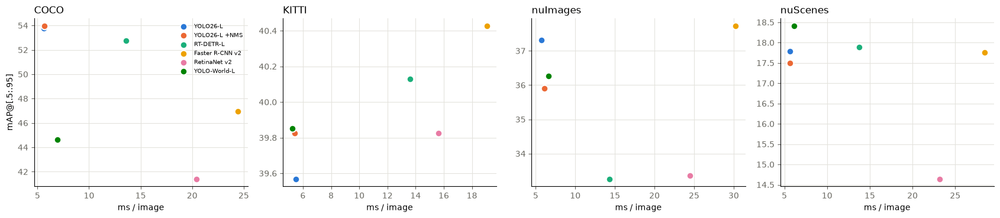

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, d in zip(axes, DS):
    for n in NAMES:
        r = res[(n, d)]; ax.scatter(r["speed"]["mean_ms"], 100 * r["metrics"]["AP"], s=70, color=COLORS[n], edgecolor="white", linewidth=1.5, zorder=3, label=n)
    ax.set_title(DSN[d], loc="left"); ax.set_xlabel("ms / image"); style(ax); ax.grid(axis="x", color="#e4e3dd", lw=0.8)
axes[0].set_ylabel("mAP@[.5:.95]"); axes[0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()

## 11. Failure analysis

In [21]:
def misses(n, d, thr=0.3):
    g = GT[d]; pr = {}
    for p in json.loads(Path(res[(n, d)]["pred_file"]).read_text()):
        if p["score"] >= thr: pr.setdefault(p["image_id"], []).append(p)
    out = []
    for a in g.dataset["annotations"]:
        if a.get("iscrowd") or a["category_id"] not in (1, 3): continue
        if not any(p["category_id"] == a["category_id"] and iou_xywh(p["bbox"], a["bbox"]) >= 0.5 for p in pr.get(a["image_id"], [])):
            out.append(a)
    return out, pr
rows = []
for d in ("kitti", "nuimages", "nuscenes"):
    tot = [a for a in GT[d].dataset["annotations"] if not a.get("iscrowd") and a["category_id"] in (1, 3)]
    for n in NAMES:
        m, _ = misses(n, d)
        row = {"Dataset": DSN[d], "Model": n, "car+person GT": len(tot), "missed": len(m), "miss %": 100 * len(m) / len(tot),
               "% small (<40px)": 100 * np.mean([a["bbox"][3] < 40 for a in m]), "% person": 100 * np.mean([a["category_id"] == 1 for a in m])}
        if d == "kitti": row["% occluded (occ≥2 / vis 40-60)"] = 100 * np.mean([a["occluded"] >= 2 for a in m])
        if d == "nuscenes": row["% occluded (occ≥2 / vis 40-60)"] = 100 * np.mean([a["visibility"] == "v40-60" for a in m])
        rows.append(row)
pd.DataFrame(rows).set_index(["Dataset", "Model"])

car+person GT  missed  miss %  % small (<40px)  \
Dataset  Model                                                             
KITTI    YOLO26-L                  4441     849    19.1             46.5   
         YOLO26-L +NMS             4441     786    17.7             46.1   
         RT-DETR-L                 4441     642    14.5             40.8   
         Faster R-CNN v2           4441     529    11.9             34.8   
         RetinaNet v2              4441     603    13.6             40.3   
         YOLO-World-L              4441    1111    25.0             51.9   
nuImages YOLO26-L                   317     194    61.2             42.8   
         YOLO26-L +NMS              317     184    58.0             43.5   
         RT-DETR-L                  317     154    48.6             42.9   
         Faster R-CNN v2            317     113    35.6             31.9   
         RetinaNet v2               317     133    42.0             49.6   
         YOLO-World-L               317     198    62.5             43.9   
nuScenes YOLO26-L                 10300    4662    45.3             24.4   
         YOLO26-L +NMS            10300    4520    43.9             24.4   
         RT-DETR-L                10300    3738    36.3             23.3   
         Faster R-CNN v2          10300    3465    33.6             19.3   
         RetinaNet v2             10300    3816    37.0             22.8   
         YOLO-World-L             10300    5708    55.4             23.6   

                          % person  % occluded (occ≥2 / vis 40-60)  
Dataset  Model                                                      
KITTI    YOLO26-L             22.3                            58.9  
         YOLO26-L +NMS        23.8                            59.2  
         RT-DETR-L            26.8                            63.6  
         Faster R-CNN v2      23.8                            69.8  
         RetinaNet v2         26.9                            61.9  
         YOLO-World-L         18.5                            53.9  
nuImages YOLO26-L             69.6                             NaN  
         YOLO26-L +NMS        69.6                             NaN  
         RT-DETR-L            75.3                             NaN  
         Faster R-CNN v2      74.3                             NaN  
         RetinaNet v2         71.4                             NaN  
         YOLO-World-L         67.2                             NaN  
nuScenes YOLO26-L             53.2                            22.7  
         YOLO26-L +NMS        54.6                            22.7  
         RT-DETR-L            59.4                            24.1  
         Faster R-CNN v2      61.6                            23.4  
         RetinaNet v2         54.9                            22.6  
         YOLO-World-L         46.7                            22.8

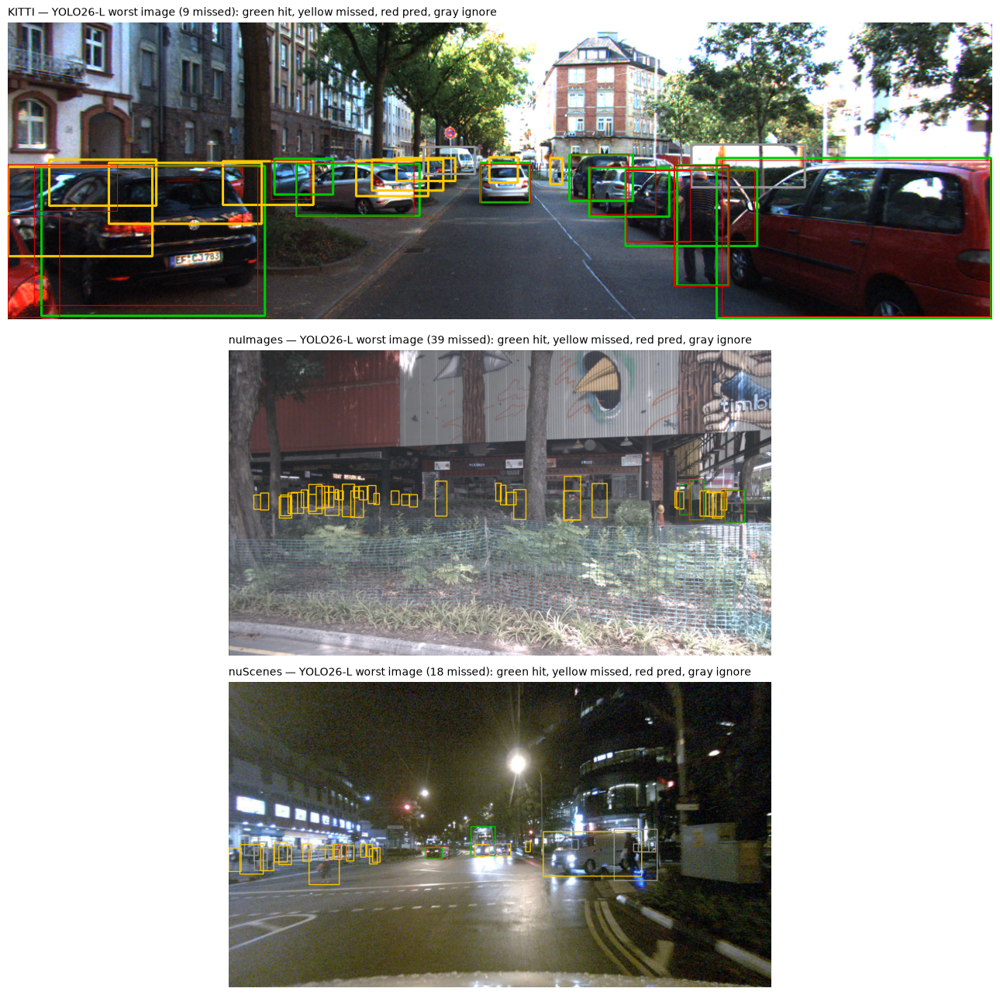

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(13, 13))
for ax, d in zip(axes, ("kitti", "nuimages", "nuscenes")):
    m, pr = misses("YOLO26-L", d)
    from collections import Counter
    img_id = Counter(a["image_id"] for a in m).most_common(1)[0][0]
    info = GT[d].imgs[img_id]; im = cv2.imread(str(Path(DS[d][1]) / info["file_name"]))
    missed_ids = {a["id"] for a in m}
    for a in GT[d].imgToAnns[img_id]:
        x, y, w, h = map(int, a["bbox"])
        col = (150, 150, 150) if a.get("iscrowd") else (0, 200, 255) if a["id"] in missed_ids else (0, 200, 0)
        cv2.rectangle(im, (x, y), (x + w, y + h), col, 2)
    for p in pr.get(img_id, []):
        if p["category_id"] in (1, 3):
            x, y, w, h = map(int, p["bbox"]); cv2.rectangle(im, (x, y), (x + w, y + h), (0, 0, 230), 1)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{DSN[d]} — YOLO26-L worst image ({sum(a['image_id'] == img_id for a in m)} missed): green hit, yellow missed, red pred, gray ignore", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 12. Conclusions

- **No single winner across domains.** On COCO: YOLO26-L 53.8 > RT-DETR-L 52.8 > Faster R-CNN 46.9 > YOLO-World-L 44.7 (zero-shot) > RetinaNet 41.4. On KITTI all six configs land within 1 AP (39.6–40.4); on nuImages Faster R-CNN and YOLO26-L lead; on nuScenes YOLO-World-L is marginally best (18.4) and RetinaNet clearly last (14.6).
- **Pedestrians are the domain-shift casualty.** Car AP: COCO ≈50 → KITTI ≈50 → nuImages ≈44 → nuScenes ≈29. Person AP: COCO ≈60 → KITTI ≈30 → nuImages ≈26 → nuScenes ≈9, even though person boxes are not smaller in the driving data.
- **Occlusion/visibility dominates.** nuScenes AP is ≈22 for 80–100% visible objects vs ≈3 for 40–60% visible (KITTI: ≈52 visible vs ≈6 largely occluded).
- **Projected 3D boxes are a weak 2D benchmark.** nuScenes AP50 (≈51) is close to nuImages (≈55–62), but AP75 collapses (≈10 vs ≈35): AP75/AP50 ≈ 0.2 vs ≈ 0.6. Most of the low nuScenes mAP is box looseness, not missed objects.
- **Open-vocabulary matches closed-set on driving data without COCO training.** YOLO-World-L is 9 AP below YOLO26-L on COCO but equal on KITTI/nuScenes. However, prompting "cyclist" does **not** recover KITTI Cyclist (AP < 1); the prompt "pedestrian" is much worse than "person" (12.5 vs 26.9 AP) — results are sensitive to prompt wording.
- **Night is a minor factor here:** nuScenes night scenes (726 images) lose only 1–3 AP vs day; YOLO26-L, RT-DETR-L and YOLO-World-L lose ≈1–2, the ResNet-50 CNNs ≈3.
- **Two-stage vs one-stage (same ResNet-50-FPN, same input):** Faster R-CNN beats RetinaNet everywhere (COCO +5.5, nuScenes +3.2) at ~1.2× the latency.
- **NMS-free models keep ~1.4–3.5 near-duplicates per 100 detections** on every dataset; NMS models ~0. YOLO26's NMS-free head has higher AR100 everywhere (+2 to +7) at equal AP.
- **Speed–accuracy:** YOLO26-L (≈5.6 ms) and YOLO-World-L (≈6 ms) are 2–5× faster than RT-DETR-L (≈14 ms), RetinaNet (≈20 ms) and Faster R-CNN (≈25 ms) with equal or better driving-domain accuracy.
- **Caveats:** nuImages is only 50 images (one fence scene with ~40 pedestrians causes ~20% of its misses); nuScenes/nuImages are the public mini splits.

## 13. References

1. Ren et al., *Faster R-CNN*, NeurIPS 2015.
2. Lin et al., *Focal Loss for Dense Object Detection (RetinaNet)*, ICCV 2017.
3. Lin et al., *Feature Pyramid Networks for Object Detection*, CVPR 2017.
4. Li et al., *Benchmarking Detection Transfer Learning with Vision Transformers*, arXiv:2111.11429 (torchvision v2 recipes).
5. Carion et al., *End-to-End Object Detection with Transformers (DETR)*, ECCV 2020.
6. Zhao et al., *DETRs Beat YOLOs on Real-time Object Detection (RT-DETR)*, CVPR 2024.
7. Wang et al., *YOLOv10: Real-Time End-to-End Object Detection*, NeurIPS 2024.
8. Cheng et al., *YOLO-World: Real-Time Open-Vocabulary Object Detection*, CVPR 2024.
9. Radford et al., *Learning Transferable Visual Models From Natural Language Supervision (CLIP)*, ICML 2021.
10. Lin et al., *Microsoft COCO*, ECCV 2014.
11. Geiger et al., *The KITTI Vision Benchmark Suite*, CVPR 2012.
12. Caesar et al., *nuScenes: A Multimodal Dataset for Autonomous Driving*, CVPR 2020 (nuImages: nuscenes.org/nuimages).
13. Ultralytics docs/code — https://docs.ultralytics.com, https://github.com/ultralytics/ultralytics
14. torchvision detection models — https://pytorch.org/vision/stable/models.html
15. nuScenes devkit (2D export reference) — https://github.com/nutonomy/nuscenes-devkit
16. pycocotools — https://github.com/cocodataset/cocoapi